# Non-AI Object Counting and Mask Overlay (OpenCV)
**Author:** Athira PT

Task: count the objects in each image and overlay a mask for each one (target: > 95 % accuracy), using classical computer vision only.

Two datasets are used:
* `Screws` - 7 images, **43 screws each** (hand-counted).
* `ScrewAndBolt` - 18 backlit images with screws **and hex nuts**, from 10 objects up to 354 touching objects (hand-counted, see `../ground_truth.csv`).

**Pipeline** (`count_and_mask.py`)
1. **Silhouette**: fit a smooth background surface (robust degree-6 polynomial), subtract, Otsu-scaled threshold.
2. **Connected components**: each blob is one object or a group of touching objects.
3. **Single-object area**: median of the smallest 65 % of blobs.
4. **Count per blob**: if the blob contains >= 2 round *nut holes*, one nut per hole, pixels assigned to the nearest hole. Otherwise `round(blob_area / single_area)`, split with k-means.
5. **Noise rejection**: tiny blobs, and small blobs touching the image border (vignette corners).

In [10]:
import os, sys, glob, csv
import cv2, numpy as np
import matplotlib.pyplot as plt

ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'Non_AI' else os.path.abspath('Athira_PT')
DATA = os.environ.get('DATA_DIR', os.path.abspath(os.path.join(ROOT, '..', 'data')))   # <repo>/data/{Screws,ScrewAndBolt}

# Load Non_AI/count_and_mask.py by explicit path under a unique name. A plain `import count_and_mask`
# can pick up the AI folder's module of the same name, or a stale copy cached in the running kernel.
import importlib.util
spec = importlib.util.spec_from_file_location('non_ai_count_and_mask', os.path.join(ROOT, 'Non_AI', 'count_and_mask.py'))
cm = importlib.util.module_from_spec(spec)
spec.loader.exec_module(cm)

GT = cm.load_ground_truth()
print('ground truth entries:', len(GT))

ground truth entries: 25


---
## 1. Why a naive threshold is not enough
A fixed global threshold fails on both datasets: the Screws images have strong vignetting (dark corners), and the nut piles in `ScrewAndBolt` are so large that a *local* background filter (median / max) treats the pile itself as background. The robust polynomial surface below is fitted only on pixels that are *not* darker than the current fit, so objects never pull it down.

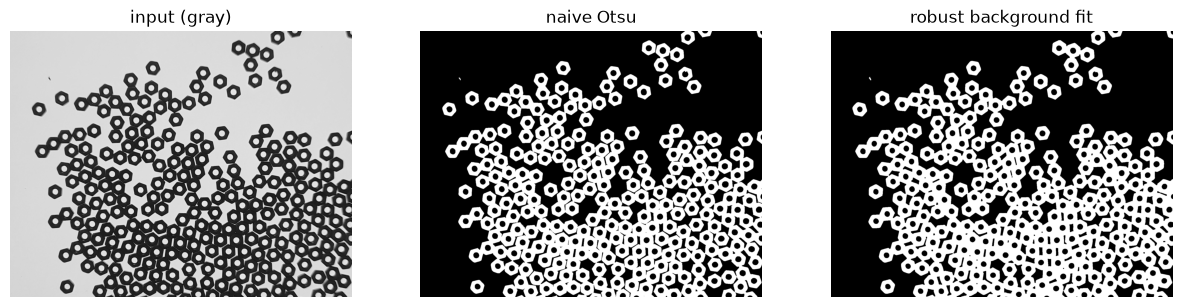

In [11]:
img = cv2.imread(os.path.join(DATA, 'ScrewAndBolt', '20240713_194551.jpg'))
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
_, naive = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
robust = cm.segment_foreground(img)

fig, ax = plt.subplots(1, 3, figsize=(15, 6))
for a, im, t in zip(ax, [gray, naive, robust], ['input (gray)', 'naive Otsu', 'robust background fit']):
    a.imshow(im[1200:2600, 600:2400], cmap='gray'); a.set_title(t); a.axis('off')
plt.show()

---
## 2. Counting nuts by their holes
Every hex nut has a bright round hole, even when the nuts touch. Round holes of consistent size are counted and the blob is split by nearest hole (Voronoi). Gap-holes between touching nuts are not round, so a circularity test (> 0.7) removes them.

count: 355  ground truth: 354


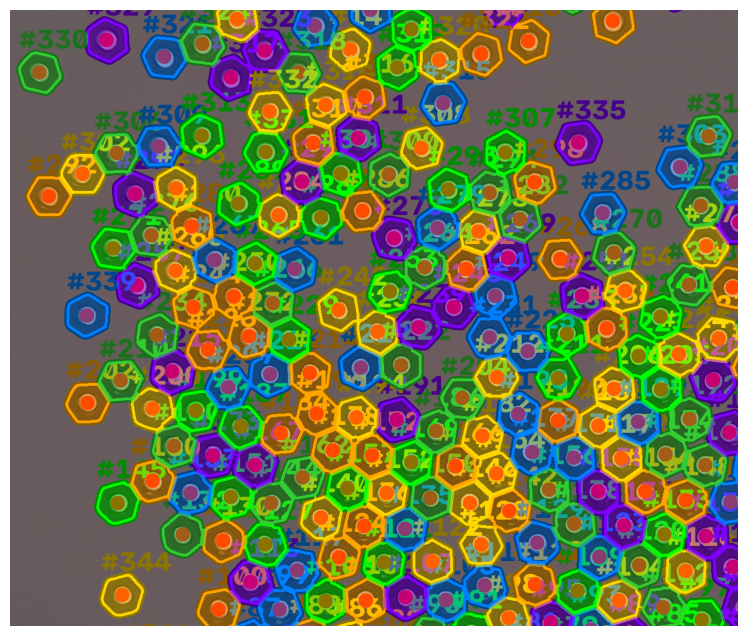

In [12]:
res = cm.detect_items_non_ai(os.path.join(DATA, 'ScrewAndBolt', '20240713_194551.jpg'))
print('count:', res['count'], ' ground truth:', GT['20240713_194551'])
plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(res['overlay_image'][1500:2600, 700:2000], cv2.COLOR_BGR2RGB)); plt.axis('off'); plt.show()

---
## 3. Benchmark on the Screws dataset (43 per image)

In [13]:
rows = cm.evaluate_dataset(os.path.join(DATA, 'Screws'))


NON-AI EVALUATION: Screws (7 images)
Filename                       | Detected  | Ground Truth | Accuracy 
------------------------------------------------------------------------------
img1.jpg                       | 43        | 43           | 100.0%
img1_43_nosy.jpg               | 43        | 43           | 100.0%
img2.jpg                       | 43        | 43           | 100.0%
img3.jpg                       | 43        | 43           | 100.0%
img4.jpg                       | 43        | 43           | 100.0%
img5.jpg                       | 43        | 43           | 100.0%
img6.jpg                       | 43        | 43           | 100.0%
------------------------------------------------------------------------------
Summary: Images=7 | Mean Accuracy=100.00% | Images > 95%: 7/7 | Worst=100.0%



---
## 4. Benchmark on the ScrewAndBolt dataset (hand-counted)

In [14]:
rows_sb = cm.evaluate_dataset(os.path.join(DATA, 'ScrewAndBolt'))


NON-AI EVALUATION: ScrewAndBolt (18 images)
Filename                       | Detected  | Ground Truth | Accuracy 
------------------------------------------------------------------------------
20240713_192951.jpg            | 24        | 21           | 85.7%
20240713_193135.jpg            | 17        | 21           | 81.0%
20240713_193650.jpg            | 10        | 10           | 100.0%
20240713_193659.jpg            | 10        | 10           | 100.0%
20240713_193831.jpg            | 194       | 193          | 99.5%
20240713_193839.jpg            | 196       | 195          | 99.5%
20240713_193907.jpg            | 193       | 193          | 100.0%
20240713_194200.jpg            | 104       | 98           | 93.9%
20240713_194206.jpg            | 102       | 99           | 97.0%
20240713_194215.jpg            | 98        | 98           | 100.0%
20240713_194232.jpg            | 98        | 98           | 100.0%
20240713_194256.jpg            | 98        | 98           | 100.0%
20240713

---
## 5. Visual gallery

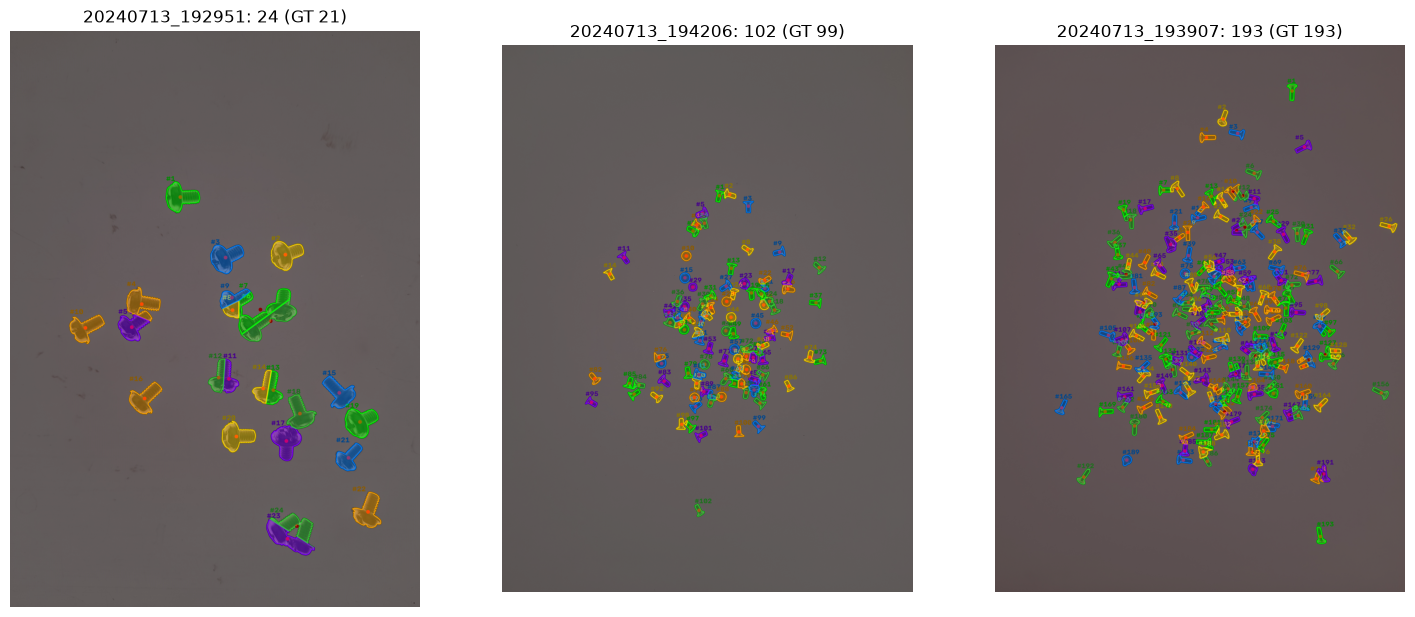

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(18, 9))
for a, name in zip(ax, ['20240713_192951', '20240713_194206', '20240713_193907']):
    r = cm.detect_items_non_ai(os.path.join(DATA, 'ScrewAndBolt', name + '.jpg'))
    a.imshow(cv2.cvtColor(r['overlay_image'], cv2.COLOR_BGR2RGB))
    a.set_title(f"{name}: {r['count']} (GT {GT[name]})"); a.axis('off')
plt.show()

---
## 6. Results (hand-counted ground truth)

| Dataset | Images | Mean accuracy | Images > 95 % |
|---|---|---|---|
| Screws | 7 | **100.0 %** | 7 / 7 |
| ScrewAndBolt | 18 | **97.5 %** | 15 / 18 |

Weak images: `192951` (24 vs 21), `193135` (17 vs 21), `194200` (104 vs 98). They contain screws that overlap each other, where area-based counting cannot tell two overlapping screws from one large one.

**Honest note:** the counting rule parameters (single-object fraction 0.65, round-to-nearest) and the hole circularity cutoff (0.7) were tuned on these same 18 hand-counted ScrewAndBolt images, so the ScrewAndBolt number is a *tuned* result, not a held-out one.